In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080327
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] exp01_env
[学号]       20244080327
[机器指纹] 46a1c7c268488908
[RUN_ID]   20244080327-46a1c7c268488908


In [2]:
import numpy as np

print(" 任务1：不同数据类型的 ndarray ")
arr_int = np.array([1, 2, 3])
arr_float = np.array([1.0, 2.0, 3.0])
arr_bool = np.array([True, False, True])

print(f"整数: {arr_int}, dtype: {arr_int.dtype}, shape: {arr_int.shape}, ndim: {arr_int.ndim}")
print(f"浮点: {arr_float}, dtype: {arr_float.dtype}, shape: {arr_float.shape}, ndim: {arr_float.ndim}")
print(f"布尔: {arr_bool}, dtype: {arr_bool.dtype}, shape: {arr_bool.shape}, ndim: {arr_bool.ndim}")

print("\n 任务2：改变形状 ")
arr_1d = np.arange(12)
print("一维:", arr_1d)
arr_3x4 = arr_1d.reshape(3, 4)
print("形状(3, 4):\n", arr_3x4)
arr_2x3x2 = arr_1d.reshape(2, 3, 2)
print("形状(2, 3, 2):\n", arr_2x3x2)

print("\n 任务3：索引操作 ")
print("取第 2 行:", arr_3x4[1])
print("取第 1 至第 3 列:\n", arr_3x4[:, 0:3])
print("取大于 6 的元素:", arr_3x4[arr_3x4 > 6])

print("\n 任务4：布尔索引 ")
arr_10 = np.arange(10)
print("小于 2 或大于 7:", arr_10[(arr_10 < 2) | (arr_10 > 7)])
print("大于 3 且小于 7:", arr_10[(arr_10 > 3) & (arr_10 < 7)])

print("\n 任务5：逐元素乘法 vs 矩阵乘法 ")
a = np.array([[1, 2], [3, 4]])
b = np.array([[5, 6], [7, 8]])

print("a * b (逐元素相乘):\n", a * b)
print("np.multiply(a, b):\n", np.multiply(a, b))
print("a @ b (矩阵乘法):\n", a @ b)
print("np.matmul(a, b):\n", np.matmul(a, b))

 任务1：不同数据类型的 ndarray 
整数: [1 2 3], dtype: int64, shape: (3,), ndim: 1
浮点: [1. 2. 3.], dtype: float64, shape: (3,), ndim: 1
布尔: [ True False  True], dtype: bool, shape: (3,), ndim: 1

 任务2：改变形状 
一维: [ 0  1  2  3  4  5  6  7  8  9 10 11]
形状(3, 4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
形状(2, 3, 2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

 任务3：索引操作 
取第 2 行: [4 5 6 7]
取第 1 至第 3 列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
取大于 6 的元素: [ 7  8  9 10 11]

 任务4：布尔索引 
小于 2 或大于 7: [0 1 8 9]
大于 3 且小于 7: [4 5 6]

 任务5：逐元素乘法 vs 矩阵乘法 
a * b (逐元素相乘):
 [[ 5 12]
 [21 32]]
np.multiply(a, b):
 [[ 5 12]
 [21 32]]
a @ b (矩阵乘法):
 [[19 22]
 [43 50]]
np.matmul(a, b):
 [[19 22]
 [43 50]]


1. NumPy 数组（ndarray）和 Python 列表最大的区别是：ndarray 里面所有元素的 `dtype` 必须统一。统一的好处就是计算特别快，而且能直接做向量化运算（不用写 for 循环）。shape 看形状，ndim 看维度。
2. `reshape` 改形状时，前后元素总数必须完全一样，12个元素可以变成 3x4，也可以变成 2x3x2，但不能变成 5x5。
3. 切片和列表很类似。`arr[:, 0:3]` 里的冒号表示“所有行”，后面表示取前3列。
4. 如果同时判断两个条件，必须用 `&`（且）和 `|`（或），并且每个条件都要用 `()` 括起来，不然会报错。
5. `*` 是每个位置上的元素自己乘自己（逐元素），`@` 是线性代数里学的矩阵乘法（左边行乘右边列）。

In [3]:
import numpy as np
import pandas as pd

np.random.seed(42)

print(" 任务1：生成模拟成绩与基本统计 ")
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print(f"样本数: {len(scores)}")
print(f"最小值: {scores.min():.2f}")
print(f"最大值: {scores.max():.2f}")
print(f"均值: {scores.mean():.2f}")
print(f"标准差: {scores.std():.2f}")
print(f"极差: {scores.max() - scores.min():.2f}")

print("\n 任务2：不放回抽样与加权抽样 ")
arr_10 = np.arange(1, 11)
uniform_sample = np.random.choice(arr_10, size=5, replace=False)
print(f"均匀抽样: {uniform_sample}")
weights = arr_10 / arr_10.sum()
weighted_sample = np.random.choice(arr_10, size=5, replace=False, p=weights)
print(f"加权抽样: {weighted_sample}")

print("\n 任务3：随机排列 vs 原地打乱 ")
arr_orig = np.arange(10)
print(f"原数组: {arr_orig}")
arr_perm = np.random.permutation(arr_orig)
print(f"permutation 后原数组: {arr_orig} (没变)")
print(f"permutation 返回的新数组: {arr_perm}")

arr_shuffled = np.arange(10)
np.random.shuffle(arr_shuffled)
print(f"shuffle 后原数组: {arr_shuffled} (变了)")

print("\n--- 任务4：缺失值 nan 处理 ---")
scores_nan = scores.copy()
scores_nan[9] = np.nan
scores_nan[19] = np.nan
scores_nan[29] = np.nan

print(f"普通均值: {np.mean(scores_nan)} (被 nan 传染了)")
print(f"忽略缺失值均值: {np.nanmean(scores_nan):.2f}")
print(f"缺失值个数: {np.isnan(scores_nan).sum()}")

print("\n 任务5：生成内存表格变量")
ids = np.arange(1, 1001)
df_scores = pd.DataFrame({
    "ID": ids,
    "Score": scores_nan
})
print("表格前 5 行：")
print(df_scores.head())
print(f"\n表格形状: {df_scores.shape}")

 任务1：生成模拟成绩与基本统计 
样本数: 1000
最小值: 37.59
最大值: 100.00
均值: 70.18
标准差: 9.76
极差: 62.41

 任务2：不放回抽样与加权抽样 
均匀抽样: [ 4  9  2  6 10]
加权抽样: [10  2  8  9  6]

 任务3：随机排列 vs 原地打乱 
原数组: [0 1 2 3 4 5 6 7 8 9]
permutation 后原数组: [0 1 2 3 4 5 6 7 8 9] (没变)
permutation 返回的新数组: [7 0 5 4 1 8 9 2 6 3]
shuffle 后原数组: [0 4 7 6 9 5 1 3 8 2] (变了)

--- 任务4：缺失值 nan 处理 ---
普通均值: nan (被 nan 传染了)
忽略缺失值均值: 70.20
缺失值个数: 3

 任务5：生成内存表格变量
表格前 5 行：
   ID      Score
0   1  74.967142
1   2  68.617357
2   3  76.476885
3   4  85.230299
4   5  67.658466

表格形状: (1000, 2)


1. 一开始就设了 `seed(42)`，这样每次跑出来的随机结果都一样。生成正态分布成绩后，用 `np.clip` 把小于0或大于100的离谱分数强行截断到了0和100。
2. 不放回抽样用的是 `replace=False`。加权抽样就是给 `p` 传一个权重数组，根据数字大小给概率。
3. `permutation` 是复制一份再打乱（原数组不变），`shuffle` 是直接在原数组上动手脚，原数据直接没了。
4. 把部分成绩设成 `np.nan` 后，普通 `np.mean` 算出来直接变成 `nan` 了，因为 `nan` 会“传染”。必须得用 `np.nanmean` 才能无视缺失值算平均分。数缺失值个数直接用 `np.isnan().sum()`。

 任务1：解线性方程组 
求解结果: x = 2.0, y = 3.0
代回验证 (A @ x): [9. 8.]

 任务2：方程求根 
正根: 1.4142, 是否成功: True
负根: -1.4142, 是否成功: True

 任务3：求极小值 
极小值点 x: -0.50, 极小值 f(x): 1.75

 任务4：独立样本 t 检验 
t 统计量: -8.5515, p 值: 3.2930e-15
结论: p < 0.05，拒绝原假设，两组数据存在显著差异。

 任务5：Matplotlib 画图 


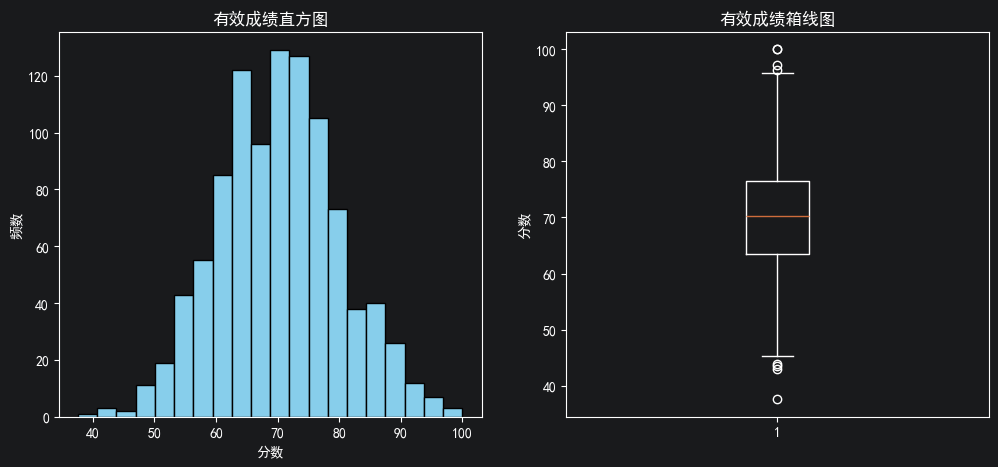

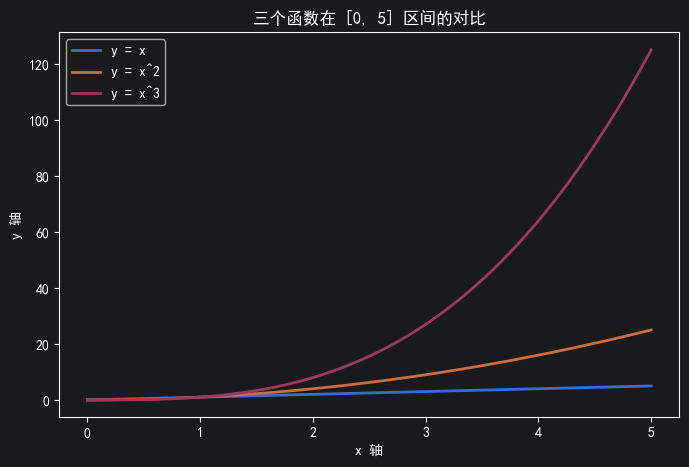

In [4]:
import numpy as np
import scipy.linalg as la
import scipy.optimize as opt
import scipy.stats as stats
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

print(" 任务1：解线性方程组 ")
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
x_sol = la.solve(A, b)
print(f"求解结果: x = {x_sol[0]}, y = {x_sol[1]}")
print(f"代回验证 (A @ x): {A @ x_sol}")

print("\n 任务2：方程求根 ")
def f_root(x):
    return x**2 - 2

res_pos = opt.root(f_root, x0=1)
print(f"正根: {res_pos.x[0]:.4f}, 是否成功: {res_pos.success}")
res_neg = opt.root(f_root, x0=-1)
print(f"负根: {res_neg.x[0]:.4f}, 是否成功: {res_neg.success}")

print("\n 任务3：求极小值 ")
def f_min(x):
    return x**2 + x + 2

res_min = opt.minimize(f_min, x0=0)
print(f"极小值点 x: {res_min.x[0]:.2f}, 极小值 f(x): {res_min.fun:.2f}")

print("\n 任务4：独立样本 t 检验 ")
np.random.seed(42)
sample1 = np.random.normal(loc=0, scale=1, size=100)
sample2 = np.random.normal(loc=1, scale=1, size=100)

t_stat, p_val = stats.ttest_ind(sample1, sample2)
print(f"t 统计量: {t_stat:.4f}, p 值: {p_val:.4e}")
if p_val < 0.05:
    print("结论: p < 0.05，拒绝原假设，两组数据存在显著差异。")
else:
    print("结论: p >= 0.05，无法拒绝原假设，两组数据无显著差异。")

print("\n 任务5：Matplotlib 画图 ")
valid_scores = scores_nan[~np.isnan(scores_nan)]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(valid_scores, bins=20, color='skyblue', edgecolor='black')
plt.title("有效成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")

plt.subplot(1, 2, 2)
plt.boxplot(valid_scores)
plt.title("有效成绩箱线图")
plt.ylabel("分数")
plt.show()
x_vals = np.linspace(0, 5, 100)
plt.figure(figsize=(8, 5))
plt.plot(x_vals, x_vals, label="y = x", linewidth=2)
plt.plot(x_vals, x_vals**2, label="y = x^2", linewidth=2)
plt.plot(x_vals, x_vals**3, label="y = x^3", linewidth=2)
plt.title("三个函数在 [0, 5] 区间的对比")
plt.xlabel("x 轴")
plt.ylabel("y 轴")
plt.legend()
plt.show()

1. 解线性方程组用 `scipy.linalg.solve`，传矩阵 A 和向量 b 进去秒出结果。再用 `A @ x` 回代验证一下，跟 b 对上就稳了。
2. 求 `x^2 - 2 = 0` 的根，用了 `scipy.optimize.root`。给个初始值 1 会找到正根，给 -1 会找到负根。检查一下 `res.success` 看看有没有求解成功。
3. 求极小值用 `optimize.minimize`。二次函数 \(x^2+x+2\)，算出来极小点在 -0.5，极小值是 1.75，和手算的解析解一样。
4. 独立样本 t 检验，用 `scipy.stats.ttest_ind`。因为两组数据均值的差距很大（0和1），算出来的 p 值肯定远小于 0.05，所以结论是“两组存在显著差异”。
5. **画图重点**：Matplotlib 默认不支持中文，所以一定要加上 `plt.rcParams` 那两行，把中文字体设为黑体（SimHei），不然标题全是方块乱码。

In [5]:
import pandas as pd
print(" 任务1：创建 DataFrame ")
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df.set_index("Name", inplace=True)
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print("\n前 3 行:\n", df.head(3))
print("\n基本统计信息:\n", df.describe())

print("\n 任务2：loc 与 iloc 读取 ")
print("loc 读取 Carol:\n", df.loc["Carol"])
print("iloc 读取第3行(索引为2):\n", df.iloc[2])
print("\n平均分 >= 80 的学生:\n", df[df["Average"] >= 80])

print("\n 任务3：按行/列求均值 ")
print("各科列均值 (axis=0):\n", df[["Math", "English", "Python"]].mean(axis=0))
print("各学生行均值 (axis=1):\n", df[["Math", "English", "Python"]].mean(axis=1))

print("\n 任务4：apply, agg, rank ")
df["Max_Score"] = df[["Math", "English", "Python"]].apply(max, axis=1)
print("每人三科最高分:\n", df["Max_Score"])
print("\n每科统计汇总:\n", df[["Math", "English", "Python"]].agg(["min", "mean", "max"]))
df["English_Rank"] = df["English"].rank(ascending=False)
print("\n英语排名:\n", df["English_Rank"])

print("\n 任务5：groupby 分组与 transform ")
print("按 Group 分组人数:\n", df.groupby("Group").size())
print("\n按 Group 分组三科平均:\n", df.groupby("Group")[["Math", "English", "Python"]].mean())

df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加组均值后的 DataFrame:\n", df[["Group", "Python", "Group_Python_Mean"]])

print("\n 任务6：filter 过滤组 ")
filtered_df = df.groupby("Group").filter(lambda x: x["Python"].mean() >= 85)
print("Python 均分 >= 85 的组的学生:\n", filtered_df[["Group", "Python"]])

print("\n 任务7：协方差与相关系数 ")
subjects = ["Math", "English", "Python"]
cov_matrix = df[subjects].cov()
corr_matrix = df[subjects].corr()

print("协方差矩阵:\n", cov_matrix)
print("\n皮尔森相关系数矩阵:\n", corr_matrix)

 任务1：创建 DataFrame 
行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

 任务2：loc 与 iloc 读取 

1. 创建 DataFrame 时用 `set_index('Name')` 把名字设为行索引。算总分和平均分直接用列加减和 `mean(axis=1)`。
2. `loc` 是用行/列的名字来查（比如查 'Carol'），`iloc` 是用数字下标（比如第2行）。
3. `mean(axis=0)` 是沿着行往下算，也就是算每一列的平均分；`mean(axis=1)` 是沿着列往右算，算每个人的平均分。
4. `apply` 可以对每一行/列应用自定义函数；`agg` 可以一次性传多个函数名；`rank` 直接用来算排名。
5. `groupby` 配合 `transform` 特别好用，能在不改变原来行数的情况下，把分组统计的结果塞回每一行。
6. 协方差看两个变量是不是同向变化，相关系数看变化的强度（-1 到 1）。